## Data Analysis for SLT responses 

In [158]:
import sys
print(sys.executable)
!{sys.executable} -m pip install matplotlib

/Users/ameny/opt/anaconda3/envs/issues/bin/python


In [159]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
print("Matplotlib is working!")
plt.style.use("ggplot")

Matplotlib is working!


In [160]:
#Loading the data

df = pd.read_csv("../data/SLT.csv", encoding="latin1")
df.head()

,ï»¿Which stakeholder are you?,Who employs you? - Selected Choice,What is your SLT band?,What is your caseload made up of? (Select all that apply) - Selected Choice,Approximately how many children do you see in a typical working week?,What percentage of your time is spent on: - Direct Intervention,What percentage of your time is spent on: - Indirect Intervention- consultations with teaching staff,What percentage of your time is spent on: - Indirect Intervention- consultations with parents and family,What percentage of your time is spent on: - Assessment and analysis of assessments,What percentage of your time is spent on: - Writing reports and referral letters,...,Please rate your level of agreement with the following statements: - Parents complete the homework with their child consistently,Please rate your level of agreement with the following statements: - I can monitor homework effectively with the parent,Please rate your level of agreement with the following statements: - School staff complete the homework with the child consistently,Please rate your level of agreement with the following statements: - I can monitor homework effectively with the school staff.,How would you describe your confidence using digital technology in your clinical work?,Do you have reliable access to the following in your primary working environment? (Select all that apply),"Who determines core pathways/management plans for service delivery in your workplace? For example, if you want to implement a new digital technology. - Selected Choice",How likely would you be to trial a digital platform that addressed the problems you described in this questionnaire?,What are the pain points that you want solved for most that will allow you to deliver therapy most efficiently?,Is there anything else you would like to inform us about?
0,Paediatric Speech and Language Therapist,NHS,Band 5,"Autism Spectrum Disorder,Developmental Languag...",6-10,NaN,1-25%,1-25%,26-50%,26-50%,...,Somewhat disagree,Somewhat disagree,Somewhat disagree,Somewhat disagree,Not at all confident: I prefer paper-based or ...,"A work-issued/private laptop,A work-issued/pri...",Integrated Care Boards,Unlikely,More tome in NHS for direct therapy rather tha...,\n
1,Paediatric Speech and Language Therapist,Private Practice,Band 7,"Autism Spectrum Disorder,AAC,Complex needs,Dev...",6-10,51-75%,NaN,1-25%,1-25%,1-25%,...,Somewhat agree,Somewhat agree,Neither agree nor disagree,Neither agree nor disagree,Extremely confident: I actively seek out new d...,"A work-issued/private laptop,A work-issued/pri...",Yourself,Very likely,Independent therapists being valued and respec...,No
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,There are challenges regarding therapists iden...,NaN
3,Paediatric Speech and Language Therapist,Other (teletherapist),Band 5,"Autism Spectrum Disorder,AAC,Cleft Palate,Deve...",6-10,26-50%,1-25%,26-50%,51-75%,26-50%,...,Somewhat agree,Somewhat agree,Somewhat agree,Somewhat agree,Extremely confident: I actively seek out new d...,"A work-issued/private laptop,A work-issued/pri...",Yourself,Very likely,access to local platforms so that the client d...,yes i want to know about the platforms where i...
4,Paediatric Speech and Language Therapist,NHS,Band 5,"Autism Spectrum Disorder,AAC,Complex needs,Dev...",6-10,1-25%,51-75%,NaN,51-75%,26-50%,...,Somewhat disagree,Strongly disagree,Somewhat disagree,Somewhat disagree,Somewhat confident: I can learn new platforms ...,"A work-issued/private laptop,A work-issued/pri...",\n,Likely,"There just isn't emough staff, and too many ch...",\n


In [161]:
# Verify the dataframe
df.shape

(42, 48)

In [162]:
df.columns

Index(['ï»¿Which stakeholder are you?', 'Who employs you? - Selected Choice',
       'What is your SLT band?',
       'What is your caseload made up of? (Select all that apply) - Selected Choice',
       'Approximately how many children do you see in a typical working week?',
       'What percentage of your time is spent on: - Direct Intervention',
       'What percentage of your time is spent on: - Indirect Intervention- consultations with teaching staff',
       'What percentage of your time is spent on: - Indirect Intervention- consultations with parents and family',
       'What percentage of your time is spent on: - Assessment and analysis of assessments',
       'What percentage of your time is spent on: - Writing reports and referral letters',
       'What percentage of your time is spent on: - Other administration duties',
       'What percentage of your time is spent on: - Meetings',
       'Other activities (please specify)',
       'Do you feel that your workload and activit

In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 48 columns):
 #   Column                                                                                                                                                                   Non-Null Count  Dtype 
---  ------                                                                                                                                                                   --------------  ----- 
 0   ï»¿Which stakeholder are you?                                                                                                                                            41 non-null     object
 1   Who employs you? - Selected Choice                                                                                                                                       41 non-null     object
 2   What is your SLT band?                                                                                  

In [164]:
# Clean 
df.columns = (
    df.columns
    .str.replace("\n", " ", regex=False)
    .str.strip()
)
df.to_csv("../data/SLT_clean.csv", index=False)

#### Employer

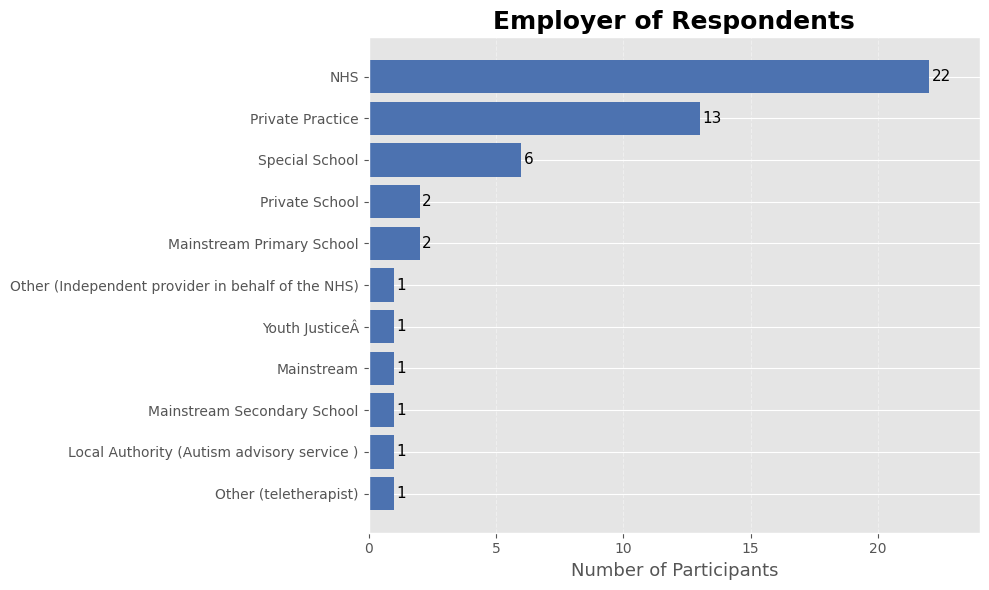

In [165]:
# Get employer counts from a multiple-choice question
employer_counts = (
    df["Who employs you? - Selected Choice"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

# Remove empty and unwanted responses
employer_counts = employer_counts[
    (employer_counts != "") &
    (employer_counts != "-") &
    (employer_counts != "Other (please specify)")
]

# Count responses
employer_counts = employer_counts.value_counts().sort_values()

# Create the plot
plt.figure(figsize=(10,6))

bars = plt.barh(
    employer_counts.index,
    employer_counts.values,
    color="#4C72B0"
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.1,
        bar.get_y() + bar.get_height()/2,
        str(int(width)),
        va="center",
        fontsize=11
    )

plt.title("Employer of Respondents", fontsize=18, fontweight="bold")
plt.xlabel("Number of Participants", fontsize=13)
plt.ylabel("")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.xlim(0, employer_counts.max() + 2)

plt.tight_layout()
plt.show()

Respondents represented a variety of employment settings. The largest proportion were employed within the NHS (n = 12), followed by private practice (n = 9). Smaller numbers worked within special schools (n = 6), private schools (n = 2), mainstream primary schools (n = 1), and local authority services (n = 1), demonstrating representation across both health and education sectors.

#### SLT Band

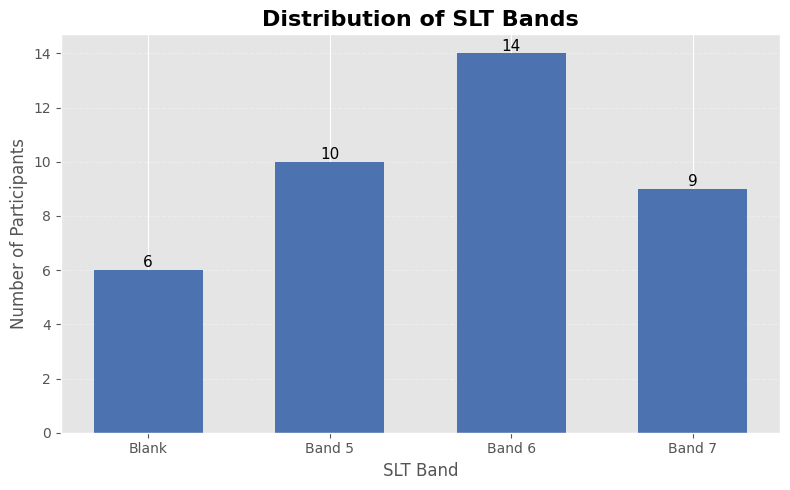

In [166]:
# Clean the Band column
band_data = (
    df["What is your SLT band?"]
    .fillna("Blank")
    .astype(str)
    .str.strip()
)

# Replace empty strings and "-" with "Blank"
band_data = band_data.replace({
    "": "Blank",
    "-": "Blank"
})

# Count responses
band_counts = band_data.value_counts()

# Order the categories
band_order = ["Blank", "Band 5", "Band 6", "Band 7", "Band 8"]

band_counts = band_counts.reindex(band_order, fill_value=0)

# Remove categories with zero responses
band_counts = band_counts[band_counts > 0]

# Plot
plt.figure(figsize=(8,5))

bars = plt.bar(
    band_counts.index,
    band_counts.values,
    color="#4C72B0",
    width=0.6
)

# Add count labels
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        int(bar.get_height()),
        ha="center",
        fontsize=11
    )

plt.title("Distribution of SLT Bands", fontsize=16, fontweight="bold")
plt.xlabel("SLT Band")
plt.ylabel("Number of Participants")

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Participants represented a range of clinical grades. Band 6 clinicians formed the largest group (n = 9), followed by Band 5 (n = 8) and Band 7 (n = 3). Five responses did not specify an NHS band, likely reflecting participants working outside NHS services. Overall, the sample primarily represented early to mid-career clinicians delivering frontline paediatric services.

#### Caseload

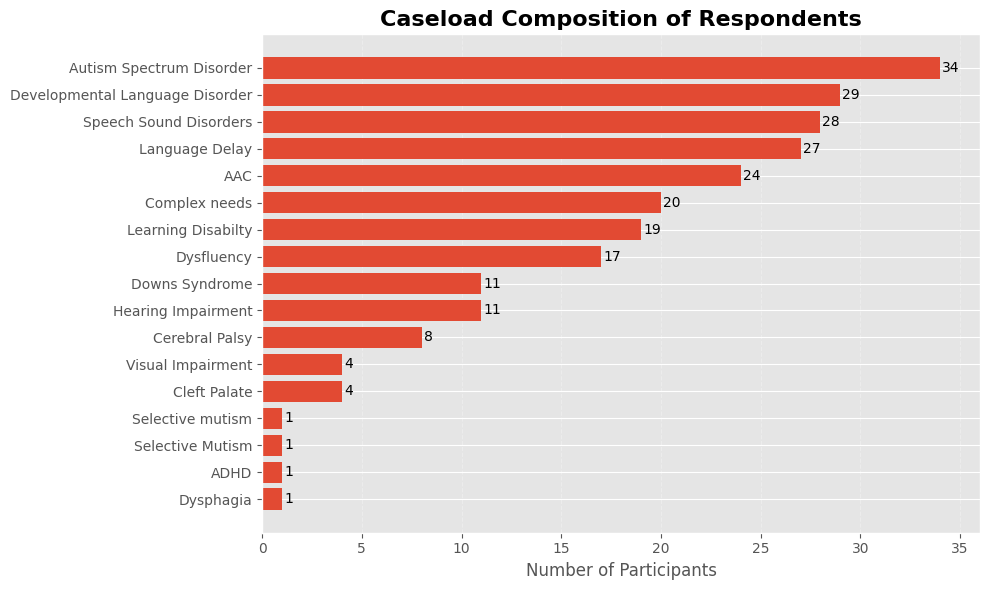

In [167]:


caseload_col = "What is your caseload made up of? (Select all that apply) - Selected Choice"

caseload_counts = (
    df[caseload_col]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

caseload_counts = caseload_counts[
    (caseload_counts != "") &
    (caseload_counts != "-") &
    (caseload_counts != "Other (please specify)")
]

caseload_counts = caseload_counts.value_counts().sort_values()

plt.figure(figsize=(10, 6))
bars = plt.barh(caseload_counts.index, caseload_counts.values)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center")

plt.title("Caseload Composition of Respondents", fontsize=16, fontweight="bold")
plt.xlabel("Number of Participants")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.xlim(0, caseload_counts.max() + 2)
plt.tight_layout()
plt.show()

SLTs reported highly varied clinical caseloads. The most frequently encountered populations included Autism Spectrum Disorder (n = 18), Speech Sound Disorders (n = 17), Developmental Language Disorder (n = 17) and children requiring Augmentative and Alternative Communication (AAC) (n = 15). Language delay (n = 14), complex needs (n = 13) and learning disability (n = 11) were also commonly represented, indicating that clinicians typically managed broad and complex caseloads rather than specialising in a single diagnostic group.

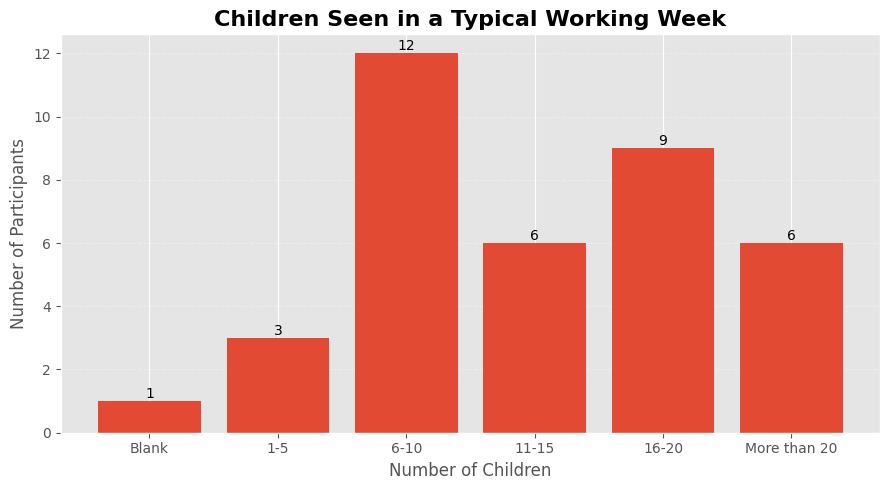

In [168]:

children_col = "Approximately how many children do you see in a typical working week?"

children_data = (
    df[children_col]
    .fillna("Blank")
    .astype(str)
    .str.strip()
)

children_data = children_data.replace({
    "\\n": "Blank",
    "\n": "Blank",
    "06-Oct": "6-10",
    "Nov-15": "11-15",
    "01-May": "1-5",
    "16–20": "16-20"
})

children_order = ["Blank", "1-5", "6-10", "11-15", "16-20", "More than 20"]

children_counts = (
    children_data
    .value_counts()
    .reindex(children_order, fill_value=0)
)

children_counts = children_counts[children_counts > 0]

plt.figure(figsize=(9,5))

bars = plt.bar(children_counts.index, children_counts.values)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        int(bar.get_height()),
        ha="center"
    )

plt.title("Children Seen in a Typical Working Week", fontsize=16, fontweight="bold")
plt.xlabel("Number of Children")
plt.ylabel("Number of Participants")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

Most therapists reported seeing between 6 and 20 children per week, with six participants seeing between 6 and 10 children, five seeing 11 to 15 children, five seeing 16 to 20 children, and three seeing more than 20 children weekly. This demonstrates considerable clinical workload across respondents.

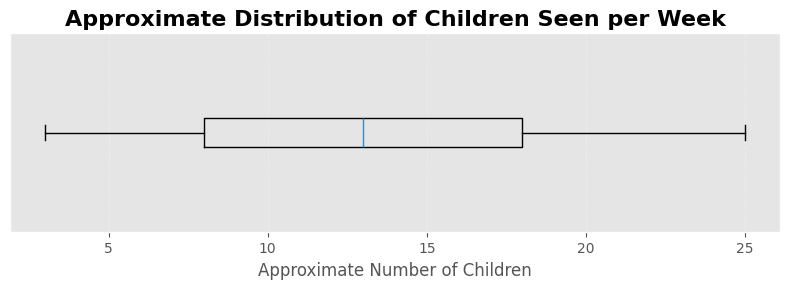

In [169]:

children_col = "Approximately how many children do you see in a typical working week?"

# Map categories to representative values
mapping = {
    "01-May": 3,        # Excel converted 1-5
    "1-5": 3,
    "06-Oct": 8,        # Excel converted 6-10
    "6-10": 8,
    "Nov-15": 13,       # Excel converted 11-15
    "11-15": 13,
    "16-20": 18,
    "More than 20": 25
}

children = (
    df[children_col]
    .replace(mapping)
)

children = pd.to_numeric(children, errors="coerce").dropna()

plt.figure(figsize=(8,3))

plt.boxplot(children, vert=False)

plt.title("Approximate Distribution of Children Seen per Week", fontsize=16, fontweight="bold")
plt.xlabel("Approximate Number of Children")
plt.yticks([])
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

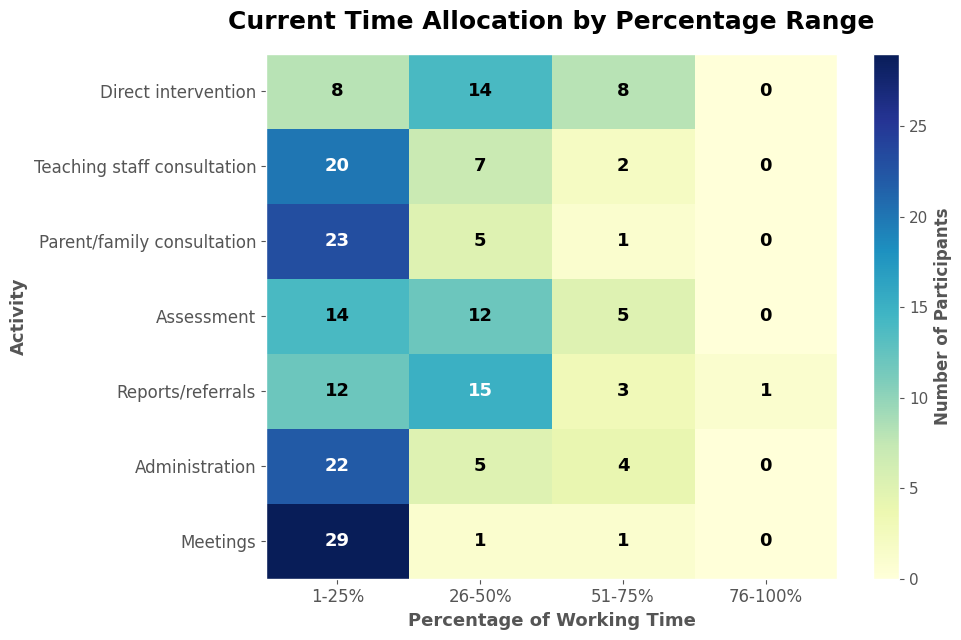

In [170]:
# Current time allocation

current_time_cols = {
    "Direct intervention": "What percentage of your time is spent on: - Direct Intervention",
    "Teaching staff consultation": "What percentage of your time is spent on: - Indirect Intervention- consultations with teaching staff",
    "Parent/family consultation": "What percentage of your time is spent on: - Indirect Intervention- consultations with parents and family",
    "Assessment": "What percentage of your time is spent on: - Assessment and analysis of assessments",
    "Reports/referrals": "What percentage of your time is spent on: - Writing reports and referral letters",
    "Administration": "What percentage of your time is spent on: - Other administration duties",
    "Meetings": "What percentage of your time is spent on: - Meetings"
}

range_order = ["1-25%", "26-50%", "51-75%", "76-100%"]


def clean_percentage_range(x):
    x = str(x).strip()

    x = (
        x.replace("–", "-")
         .replace("—", "-")
         .replace("01-25", "1-25")
    )

    if x in ["", "-", "\\n", "\n", "nan", "None"]:
        return None

    if not x.endswith("%"):
        x += "%"

    return x


# Create table
heatmap_data = pd.DataFrame(
    index=current_time_cols.keys(),
    columns=range_order
)

for activity, col in current_time_cols.items():
    cleaned = df[col].apply(clean_percentage_range)
    counts = cleaned.value_counts()

    for r in range_order:
        heatmap_data.loc[activity, r] = counts.get(r, 0)

heatmap_data = heatmap_data.astype(int)

# ---------------- Plot ---------------- #

plt.figure(figsize=(10, 6.5))

im = plt.imshow(
    heatmap_data.values,
    cmap="YlGnBu",
    aspect="auto"
)

plt.xticks(
    range(len(range_order)),
    range_order,
    fontsize=12
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index,
    fontsize=12
)

plt.xlabel(
    "Percentage of Working Time",
    fontsize=13,
    fontweight="bold"
)

plt.ylabel(
    "Activity",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "Current Time Allocation by Percentage Range",
    fontsize=18,
    fontweight="bold",
    pad=18
)

# Cell values
threshold = heatmap_data.values.max() / 2

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):

        value = heatmap_data.iloc[i, j]

        colour = "white" if value > threshold else "black"

        plt.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color=colour
        )

cbar = plt.colorbar(im)
cbar.set_label(
    "Number of Participants",
    fontsize=12,
    fontweight="bold"
)
cbar.ax.tick_params(labelsize=11)
plt.grid(False)
plt.tight_layout()
plt.show()

| Activity            | 1-25% | 26-50% | 51-75% | 76-100% |
| ------------------- | ----- | ------ | ------ | ------- |
| Direct intervention | 3     | 11     | 8      | 3       |
| Assessment          | 9     | 12     | 4      | 0       |
| Reports             | 10    | 8      | 6      | 1       |
| Meetings            | 18    | 6      | 1      | 0       |


Participants reported mixed perceptions regarding whether their workload made the best use of their time and professional skills. The largest proportion of respondents selected "Moderately / Neutral" (n = 7), followed by "Mostly / To a great extent" (n = 5) and "Slightly" (n = 4). Fewer respondents felt that their workload made the best use of their skills "Completely / To a very great extent" (n = 2) or "Not at all" (n = 2). Five respondents did not provide a response to this question.

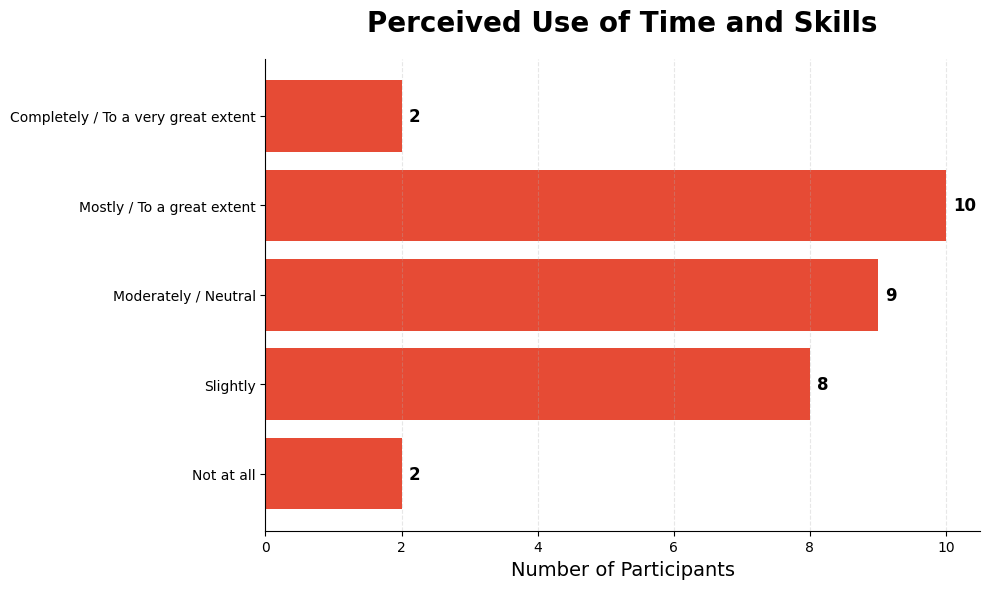

Blank responses excluded from plot: 11


In [171]:
# Workload makes best use of time 

# Column name
col = "Do you feel that your workload and activities (as reflected in previous question) makes the best use of your time and skills?"

# Clean responses
responses = df[col].astype(str).str.strip()

# Count missing responses
blank_count = responses.isin(["", "\\n", "\n", "-", "nan", "None"]).sum()

# Remove blanks
responses = responses[~responses.isin(["", "\\n", "\n", "-", "nan", "None"])]

# Desired order
order = [
    "Not at all",
    "Slightly",
    "Moderately / Neutral",
    "Mostly / To a great extent",
    "Completely / To a very great extent"
]

# Count responses
counts = responses.value_counts().reindex(order, fill_value=0)

# Plot
plt.style.use("default")

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.barh(
    counts.index,
    counts.values,
    color="#E64B35"
)

# Add numbers
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.1,
        bar.get_y() + bar.get_height()/2,
        f"{int(width)}",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Perceived Use of Time and Skills",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Number of Participants", fontsize=14)
ax.set_ylabel("")

ax.grid(axis="x", linestyle="--", alpha=0.3)

# Remove top/right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Blank responses excluded from plot: {blank_count}")

When asked whether their workload represented the best use of their professional time and expertise, responses suggested considerable dissatisfaction. Many clinicians indicated that their current workload only moderately reflected the best use of their skills, while relatively few believed their time was being used to a very great extent. These findings suggest that administrative responsibilities and competing service demands continue to reduce opportunities for direct clinical intervention.

In [172]:
def clean_response(x):
    x = str(x).strip()
    if x in ["", "-", "\\n", "\n", "nan", "None"]:
        return None
    return x


def plot_single_choice(column, title, order=None, exclude_blank=True):
    data = df[column].apply(clean_response)

    blank_count = data.isna().sum()

    if exclude_blank:
        data = data.dropna()
    else:
        data = data.fillna("Blank")

    counts = data.value_counts()

    if order:
        counts = counts.reindex(order, fill_value=0)
        counts = counts[counts > 0]
    else:
        counts = counts.sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

    print(f"Blank responses excluded: {blank_count}")


def plot_multiple_choice(column, title, exclude_values=None):
    if exclude_values is None:
        exclude_values = ["", "-", "Other (please specify)", "\\n", "\n", "nan", "None"]

    data = (
        df[column]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    data = data[~data.isin(exclude_values)]

    counts = data.value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [173]:
def plot_likert(columns_dict, title, response_order):
    table = pd.DataFrame(index=columns_dict.keys(), columns=response_order)

    for statement, col in columns_dict.items():
        data = df[col].apply(clean_response).dropna()
        counts = data.value_counts()

        for response in response_order:
            table.loc[statement, response] = counts.get(response, 0)

    table = table.astype(int)

    fig, ax = plt.subplots(figsize=(12, 7))

    im = ax.imshow(table.values, cmap="YlGnBu", aspect="auto", interpolation="nearest")

    ax.set_xticks(range(len(response_order)))
    ax.set_xticklabels(response_order, rotation=30, ha="right", fontsize=11)

    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index, fontsize=11)

    ax.set_title(title, fontsize=18, fontweight="bold", pad=18)
    ax.set_xlabel("Response")
    ax.set_ylabel("Statement")

    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(False)

    threshold = table.values.max() / 2 if table.values.max() else 0

    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.iloc[i, j]
            colour = "white" if value > threshold else "black"

            ax.text(j, i, str(value), ha="center", va="center", fontsize=12, fontweight="bold", color=colour)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Number of Participants", fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

    return table

#### Teletherapy

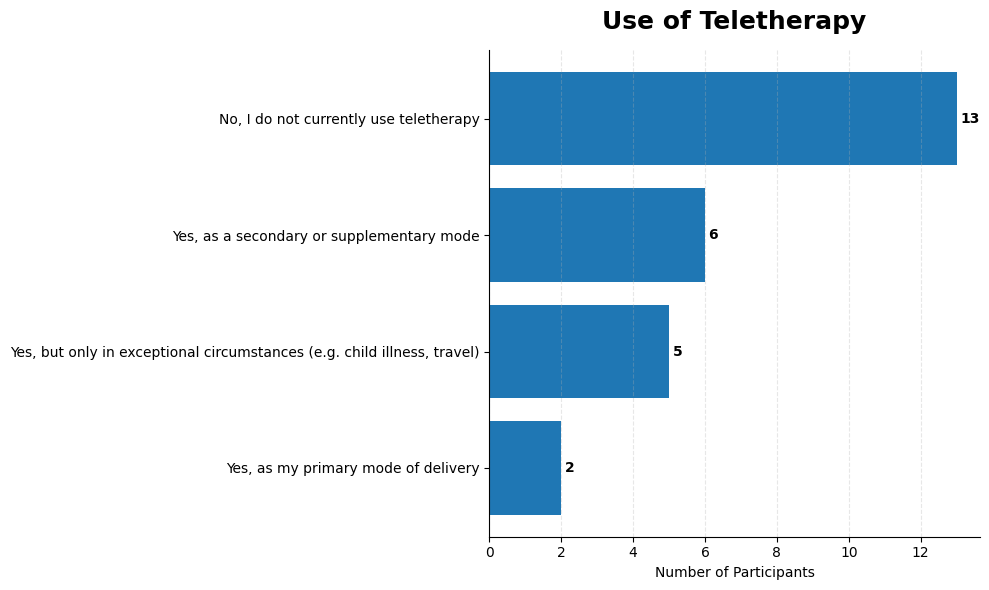

Blank responses excluded: 16


In [174]:
plot_single_choice(
    "Do you currently deliver any therapy via teletherapy (live video call)?",
    "Use of Teletherapy"
)

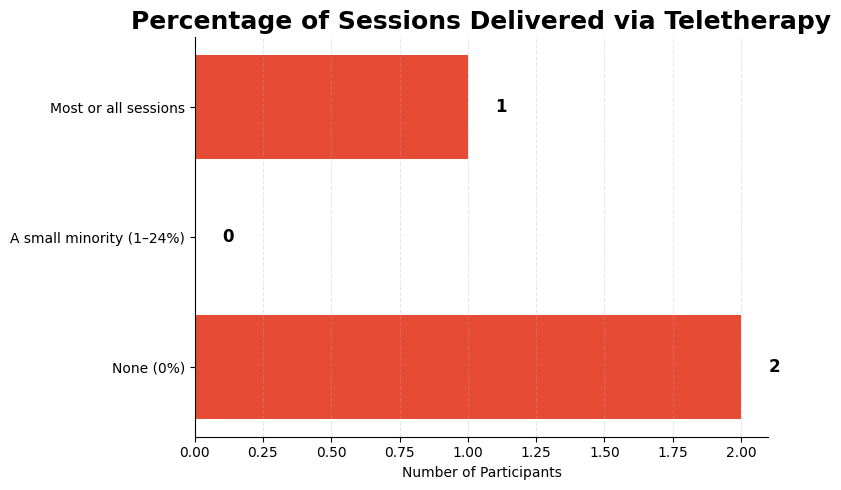

Blank responses: 30


In [175]:
tele_col = "Approximately what percentage of your current sessions are delivered via teletherapy?"

# Clean the responses
tele = (
    df[tele_col]
    .astype(str)
    .str.strip()
    .replace({
        "\\n": None,
        "\n": None,
        "": None,
        "nan": None,
        "A small minority (124%)": "A small minority (1–24%)"
    })
)

counts = (
    tele.dropna()
        .value_counts()
        .reindex([
            "None (0%)",
            "A small minority (1–24%)",
            "Most or all sessions"
        ], fill_value=0)
)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.barh(counts.index, counts.values, color="#E64B35")

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.1,
        bar.get_y() + bar.get_height()/2,
        int(width),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title(
    "Percentage of Sessions Delivered via Teletherapy",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Number of Participants")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

print("Blank responses:", tele.isna().sum())

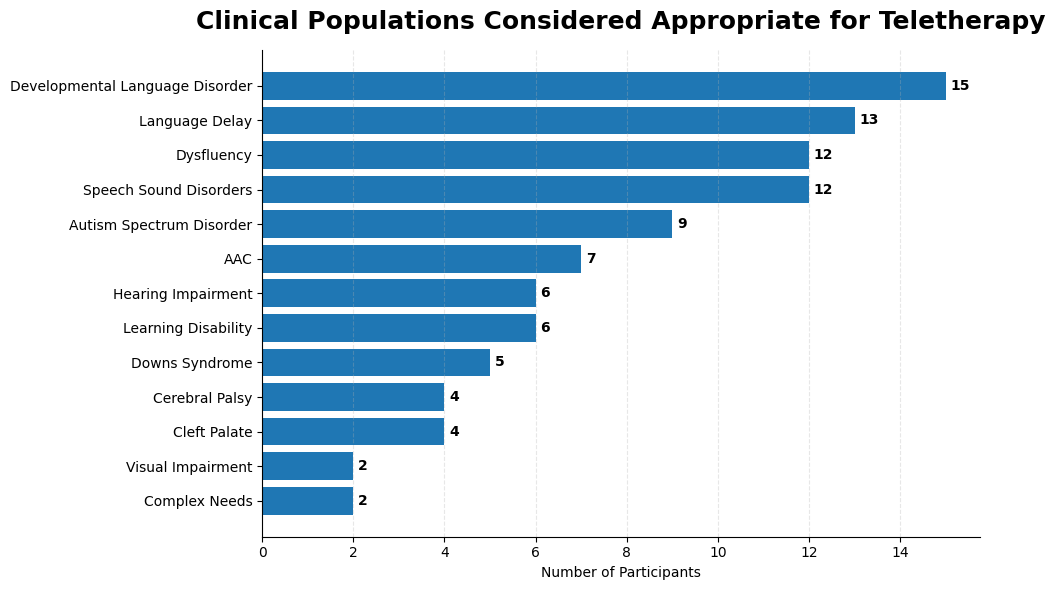

In [176]:
plot_multiple_choice(
    "Which clinical populations do you consider teletherapy to be appropriate for? (Select all that apply) - Selected Choice",
    "Clinical Populations Considered Appropriate for Teletherapy"
)

SLTs considered teletherapy appropriate for a range of clinical populations, although suitability varied according to individual communication needs. Responses suggested that teletherapy was viewed as an adjunct rather than a replacement for face-to-face intervention, reflecting the need for clinical judgement when selecting appropriate service delivery models.

#### Satisfaction

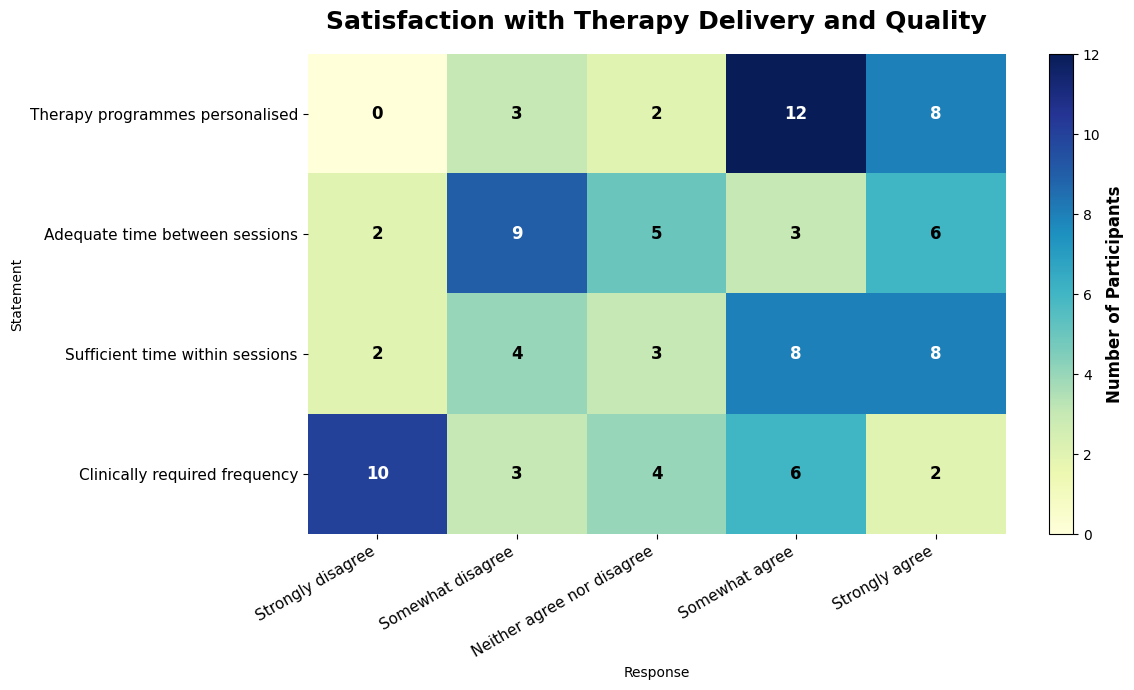

In [177]:
satisfaction_cols = {
    "Therapy programmes personalised": "Please rate your satisfaction with these statements about therapy delivery and quality - Current therapy programmes are sufficiently personalised to each child's needs",
    "Adequate time between sessions": "Please rate your satisfaction with these statements about therapy delivery and quality - I have adequate time between sessions to monitor and document progress",
    "Sufficient time within sessions": "Please rate your satisfaction with these statements about therapy delivery and quality - I have sufficient time within each session to assess and adapt my approach",
    "Clinically required frequency": "Please rate your satisfaction with these statements about therapy delivery and quality - Children I work with receive the session frequency they clinically require"
}

satisfaction_order = [
    "Strongly disagree",
    "Somewhat disagree",
    "Neither agree nor disagree",
    "Somewhat agree",
    "Strongly agree"
]

satisfaction_table = plot_likert(
    satisfaction_cols,
    "Satisfaction with Therapy Delivery and Quality",
    satisfaction_order
)

Participants generally reported positive perceptions regarding the quality and personalisation of therapy. Most agreed that intervention programmes were sufficiently individualised to meet children's needs and that they had adequate opportunity within therapy sessions to adapt their approach according to individual progress.

However, satisfaction was notably lower regarding available time between sessions and therapy frequency. Several respondents indicated that they lacked sufficient time to monitor progress adequately between appointments, while many also disagreed that children were receiving therapy at the frequency they clinically required. These findings highlight ongoing service capacity pressures affecting paediatric speech and language therapy provision.



#### Homework

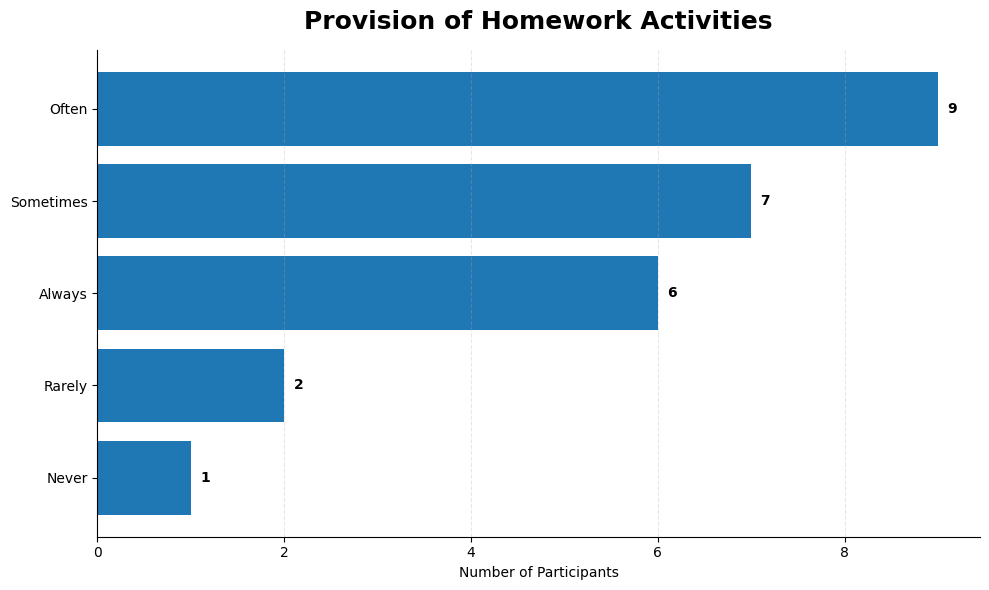

Blank responses excluded: 17


In [178]:
plot_single_choice(
    "Do you give homework activities to the children you see for therapy?",
    "Provision of Homework Activities"
)

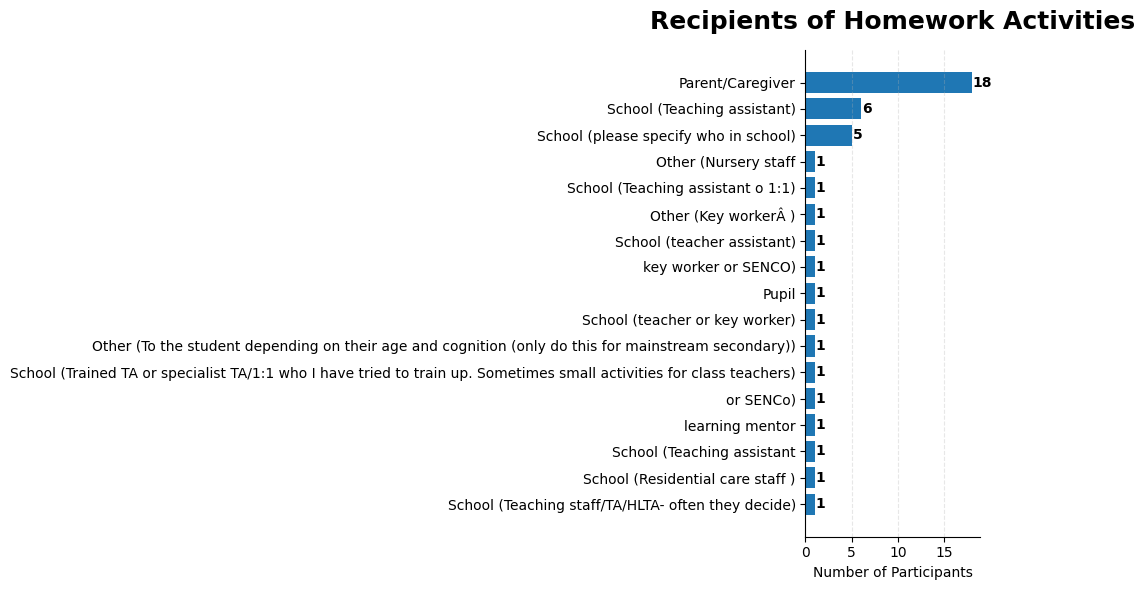

In [179]:
plot_multiple_choice(
    "Who do you give homework activities for the children to? (Select all that apply) - Selected Choice",
    "Recipients of Homework Activities"
)

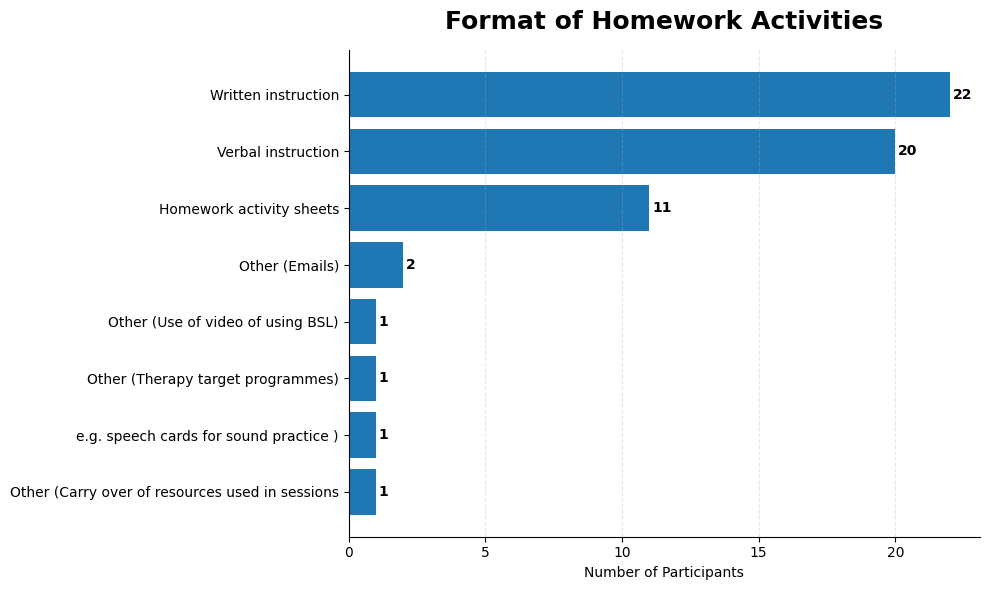

In [180]:
plot_multiple_choice(
    "What form does this homework usually take? (Select as many as apply) - Selected Choice",
    "Format of Homework Activities"
)

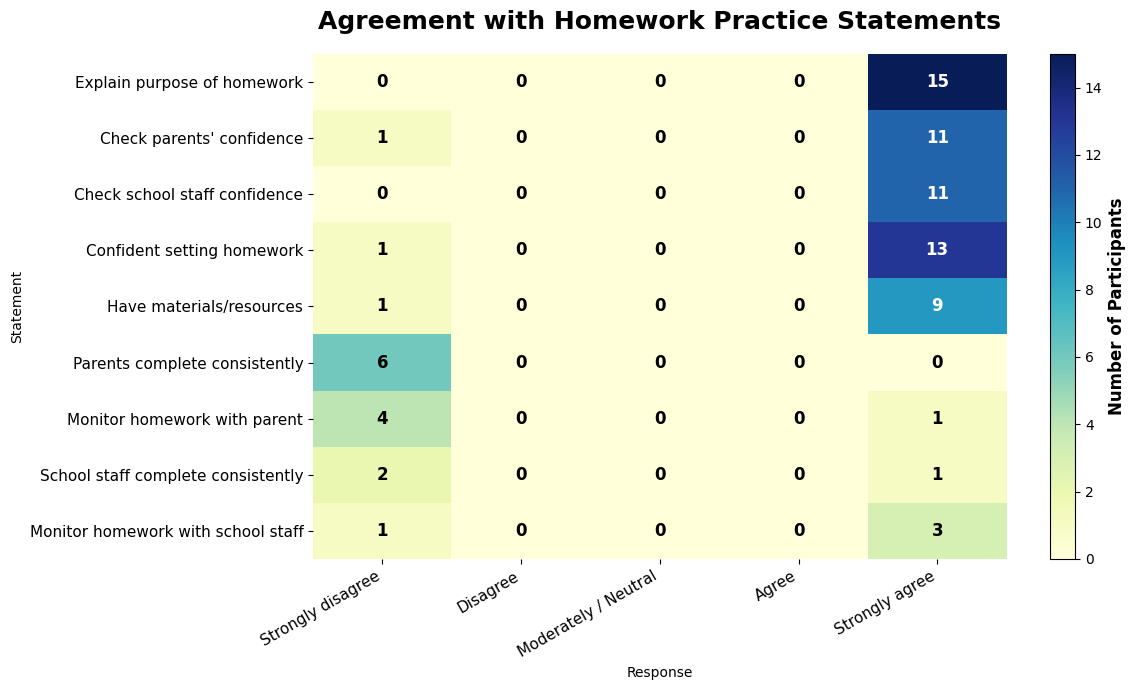

In [181]:
homework_cols = {
    "Explain purpose of homework": "Please rate your level of agreement with the following statements: - I explain the purpose of homework",
    "Check parents' confidence": "Please rate your level of agreement with the following statements: - I check in with parents about their confidence in completing homework with the child.",
    "Check school staff confidence": "Please rate your level of agreement with the following statements: - I check in with school staff about their confidence in completing homework with the child.",
    "Confident setting homework": "Please rate your level of agreement with the following statements: - I feel confident in setting homework",
    "Have materials/resources": "Please rate your level of agreement with the following statements: - I have materials/resources I need to set homework",
    "Parents complete consistently": "Please rate your level of agreement with the following statements: - Parents complete the homework with their child consistently",
    "Monitor homework with parent": "Please rate your level of agreement with the following statements: - I can monitor homework effectively with the parent",
    "School staff complete consistently": "Please rate your level of agreement with the following statements: - School staff complete the homework with the child consistently",
    "Monitor homework with school staff": "Please rate your level of agreement with the following statements: - I can monitor homework effectively with the school staff."
}

agreement_order = [
    "Strongly disagree",
    "Disagree",
    "Moderately / Neutral",
    "Agree",
    "Strongly agree"
]

homework_table = plot_likert(
    homework_cols,
    "Agreement with Homework Practice Statements",
    agreement_order
)

Homework formed a routine component of intervention for the majority of respondents. Therapists commonly provided home practice activities to both parents and school staff, reflecting a collaborative approach to supporting children's communication outside therapy sessions. 

Homework frequently consisted of structured activities, practical communication strategies and therapy exercises designed to reinforce skills across home and educational environments.

Respondents generally expressed confidence in setting homework and reported that they routinely explained its purpose to families and educational professionals. Nevertheless, responses suggested lower confidence regarding monitoring homework completion and ensuring consistent implementation by parents and school staff. 

> This indicates that while clinicians value collaborative practice, maintaining intervention fidelity outside therapy sessions remains challenging.

#### Digital Technology 

In [182]:
col = "How would you describe your confidence using digital technology in your clinical work?"

df[col].value_counts(dropna=False)

How would you describe your confidence using digital technology in your clinical work?
\n                                                                            16
Very confident: I quickly adopt new digital tools                              9
Somewhat confident: I can learn new platforms with some guidance               8
Extremely confident: I actively seek out new digital tools for my practice     6
Not at all confident: I prefer paper-based or face-to-face methods             1
NaN                                                                            1
Not so confident: I use basic tools but struggle with new platforms            1
Name: count, dtype: int64

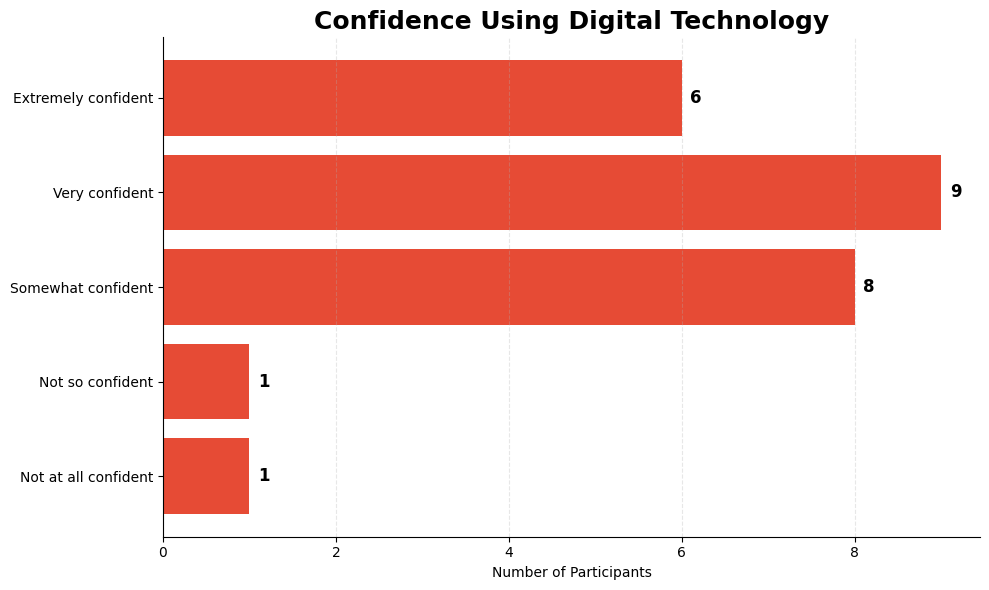

In [183]:
confidence_map = {
    "Not at all confident: I prefer paper-based or face-to-face methods":
        "Not at all confident",
    "Not so confident: I use basic tools but struggle with new platforms":
        "Not so confident",
    "Somewhat confident: I can learn new platforms with some guidance":
        "Somewhat confident",
    "Very confident: I quickly adopt new digital tools":
        "Very confident",
    "Extremely confident: I actively seek out new digital tools for my practice":
        "Extremely confident"
}

confidence = (
    df["How would you describe your confidence using digital technology in your clinical work?"]
    .replace(confidence_map)
)

counts = confidence.value_counts().reindex([
    "Not at all confident",
    "Not so confident",
    "Somewhat confident",
    "Very confident",
    "Extremely confident"
], fill_value=0)

plt.style.use("default")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(counts.index, counts.values, color="#E64B35")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.1,
            bar.get_y() + bar.get_height()/2,
            int(width),
            va="center",
            fontsize=12,
            fontweight="bold")

ax.set_title("Confidence Using Digital Technology", fontsize=18, fontweight="bold")
ax.set_xlabel("Number of Participants")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

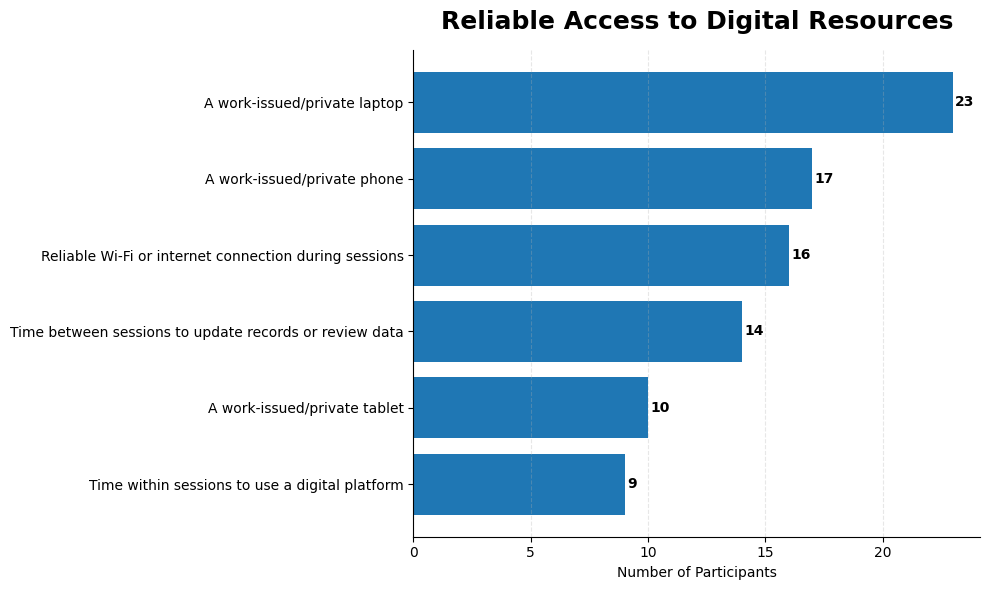

In [184]:
plot_multiple_choice(
    "Do you have reliable access to the following in your primary working environment? (Select all that apply)",
    "Reliable Access to Digital Resources"
)

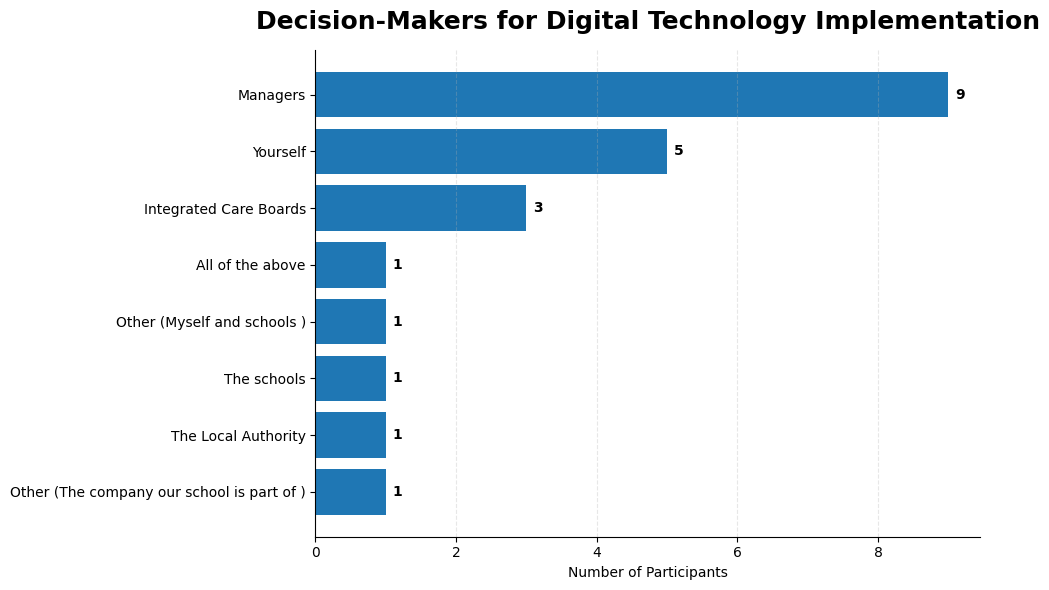

Blank responses excluded: 20


In [185]:
plot_single_choice(
    "Who determines core pathways/management plans for service delivery in your workplace? For example, if you want to implement a new digital technology. - Selected Choice",
    "Decision-Makers for Digital Technology Implementation"
)

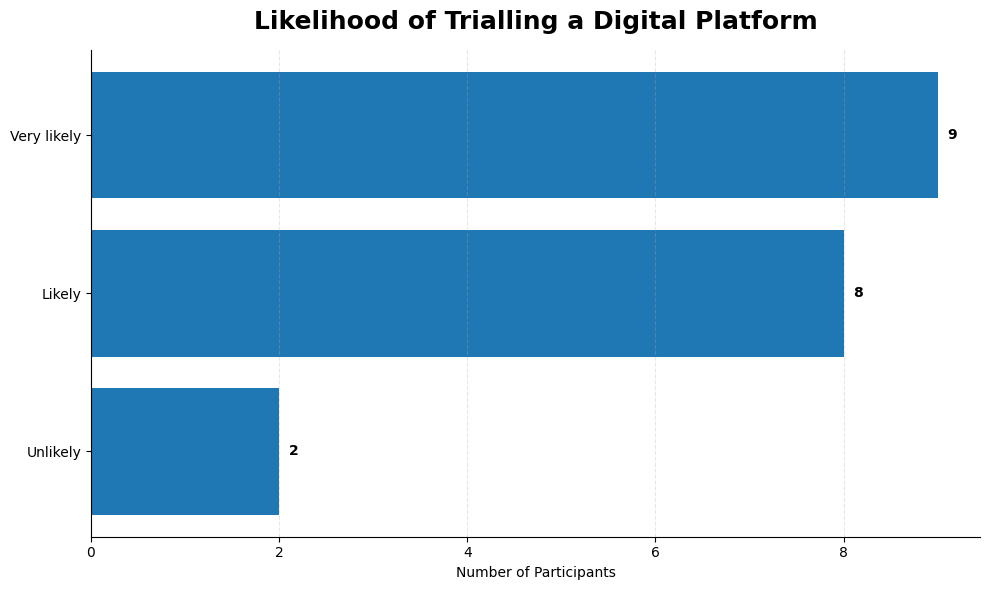

Blank responses excluded: 18


In [186]:
plot_single_choice(
    "How likely would you be to trial a digital platform that addressed the problems you described in this questionnaire?",
    "Likelihood of Trialling a Digital Platform",
    order=[
        "Very unlikely",
        "Unlikely",
        "Moderately / Neutral",
        "Likely",
        "Very likely"
    ]
)

The majority of clinicians indicated that they would be likely or very likely to trial a digital platform capable of addressing current service challenges. Qualitative responses suggested that therapists were particularly interested in technologies capable of reducing administrative workload, improving communication with families and schools, supporting homework implementation, and increasing therapy efficiency.

# Overall 

SLT survey highlights the complexity of contemporary paediatric speech and language therapy practice. Respondents managed diverse and clinically complex caseloads while balancing direct intervention with substantial indirect clinical responsibilities. Although clinicians generally reported confidence in their clinical skills and digital technology use, dissatisfaction regarding workload distribution, therapy frequency and administrative burden suggests ongoing workforce and service pressures. The strong willingness to adopt digital solutions further indicates an appetite for innovations that support efficient, collaborative and family-centred service delivery.